In [17]:
#9.Write a python program to illustrate ART neural network: Clustering 2D Data Using ART1-
#a. Implement the ART1 algorithm for binary input data.
#b. Given a set of binary vectors, cluster them into categories based on similarity.
#c. Use vigilance parameter (ρ) to control cluster formation. Clustering 2D Data using Winner-Takes-All (WTA)
#Network Implement a Winner-Takes-All (WTA) neural network to cluster 2D data points.
#d. Each neuron represents a cluster center, and only the winning neuron (closest to input) updates its weights.
#e. Train the network on randomly generated 2D points and visualize the clusters.

ART1 Clustering
[1 1 1 0 0 0] -> Cluster 1
[1 1 0 0 0 0] -> Cluster 1
[1 1 1 0 0 0] -> Cluster 2
[0 0 0 1 1 1] -> Cluster 3
[0 0 0 1 1 0] -> Cluster 3
[0 0 0 1 1 1] -> Cluster 4
Number of clusters: 4

WTA Cluster Centers:
[[1.9051624  1.95777959]
 [5.23486173 6.92941528]
 [6.93905017 3.34671587]]


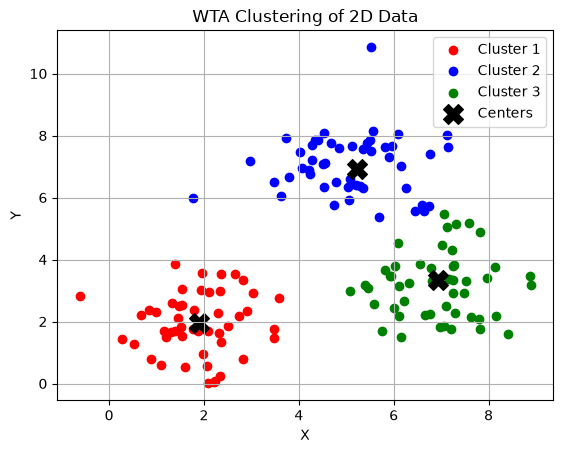

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# ART1 - Clustering Binary Data
# =========================================================

data = np.array([
    [1, 1, 1, 0, 0, 0],
    [1, 1, 0, 0, 0, 0],
    [1, 1, 1, 0, 0, 0],
    [0, 0, 0, 1, 1, 1],
    [0, 0, 0, 1, 1, 0],
    [0, 0, 0, 1, 1, 1]
])

rho = 0.7                 # Vigilance parameter
weights = []              # Cluster prototypes
clusters = []

for x in data:

    found = False

    # Check existing clusters
    for i in range(len(weights)):

        w = weights[i]

        # Similarity / match
        similarity = np.sum(x * w) / np.sum(x)

        if similarity >= rho:
            # ART1 learning
            weights[i] = x * w
            clusters.append(i)
            found = True
            break

    # Create a new cluster
    if not found:
        weights.append(x.copy())
        clusters.append(len(weights) - 1)


print("ART1 Clustering")
for i in range(len(data)):
    print(data[i], "-> Cluster", clusters[i] + 1)

print("Number of clusters:", len(weights))


# =========================================================
# WTA - Clustering 2D Data
# =========================================================

np.random.seed(42)

# Generate 2D data
data2 = np.vstack([
    np.random.randn(50, 2) + [2, 2],
    np.random.randn(50, 2) + [7, 3],
    np.random.randn(50, 2) + [5, 7]
])

# Number of clusters
k = 3

# Random cluster centers
centers = np.random.rand(k, 2) * 10

learning_rate = 0.1

# Training
for epoch in range(20):

    for x in data2:

        # Find distance from x to every center
        distances = np.linalg.norm(centers - x, axis=1)

        # Winner = closest center
        winner = np.argmin(distances)

        # Update only winner
        centers[winner] = centers[winner] + \
            learning_rate * (x - centers[winner])


# Assign points to clusters
clusters2 = []

for x in data2:

    distances = np.linalg.norm(centers - x, axis=1)
    winner = np.argmin(distances)

    clusters2.append(winner)

clusters2 = np.array(clusters2)


# =========================================================
# Display Results
# =========================================================

print("\nWTA Cluster Centers:")
print(centers)


# Plot clusters
colors = ["red", "blue", "green"]

for i in range(k):
    points = data2[clusters2 == i]

    plt.scatter(
        points[:, 0],
        points[:, 1],
        color=colors[i],
        label="Cluster " + str(i + 1)
    )

# Plot centers
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    color="black",
    marker="X",
    s=200,
    label="Centers"
)

plt.title("WTA Clustering of 2D Data")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.grid()
plt.show()
